# Pour résumer

## Nettoyage
J'ai conservé les colonnes `NaN` de `parent_registration_number` dans `registered_entities` l'absence de déclaration d'une société-mère sera peut-être utile ensuite ?

---

## Longévité et anomalies 
L'analyse de `public_appointments` montre des durées de mandat délirantes :  

La durée moyenne d'un mandat est de 19,10 ans avec une médiane de 14,33 ans. Par contre on voit qu'Elira Vaun a une valeur aberrante avec un mandat cumulé de 56,71 ans  

On prend 2026 comme référence pour les mandats actifs (`is_active_mandate`), 7 dirigeants conservent leurs fonctions depuis 36 à 52 ans sans interruption :
  * Mirek Talven : 52 ans de mandat (84 ans en 2026) 
  * Leora Kassen : 48 ans de mandat (79 ans en 2026) 
  * Zalia Maren : 46 ans de mandat (79 ans en 2026) 
  * Tavian Serat : 42 ans de mandat (73 ans en 2026)  
Il y a une note médicale confidentielle `PUB-510045`, qui décrit un suivi clinique privilégié assurant une longévité anormale à un cercle fermé de hauts dignitaires ?..«compare biological-age estimates with chronological age » et « not the same combination of recurrence, biological-age divergence, and tightly clustered specialist facilities. » (`public_and_investigative_documents` ne contient que 40 documents c'était simple à trouver)
---

## Accès
En se concentrant sur les dossiers de demandes d'accès aux grottes (`site_access_case_events`)  :  
**Horizon Field Research Cooperative** concentre à elle seule 18 dossiers (soit 30% du total)  
**Matrice de co-occurrences  :** Le matériel `portable monitoring and cold-storage equipment` est visiblement un grand secret : 42,9 % en accès confidentiel et 42,9 % en accès restreint (85,8 % d'opacité contre seulement 14,3 % en accès standard)  
**Règle d'association `{Cold-Storage Equipment} -> {Horizon Field Research Cooperative}` :**
  * Support : 7 dossiers sur 60 (11,7 %).
  * Confiance : **100 %** (l'intégralité des équipements réfrigérés mobiles est demandée par Horizon).
  * Lift : **3,33** (très forte dépendance statistique positive).

---

## Anomalies temporelles
L'analyse temporelle semble montrer des traces de dissimulation d'activités

Quasi toutes les organisations font du 17h00 - 11h00. Par contre 100 % des expéditions d'Horizon commencent à 18h00 et s'achèvent à **03h00**, tout en ayant une étape obligatoire de `security_review` (12 cas) absente chez les autres

**Activité post-mortem :** Elira Vaun, déclarée officiellement décédée le 18 septembre 2021 dans `public_appointments`, signe et autorise **6 dossiers d'accès entre février 2022 et août 2024**.
**Anachronismes :** Trois fondateurs d'entités créées aux XIXe et XXe siècles réapparaissent comme agents opérationnels sur le terrain entre 2015 et 2025 :
  * J. Varlan (société fondée en 1883) : 9 événements récents.
  * Jonah Bell (société fondée en 1923) : 9 événements récents.
  * Julien Marot (société fondée en 1969) : 5 événements récents.
  
**Des sociétés écrans ?** Les entreprises dissoutes dans `registered_entities` se relaient par cycles d'à peu près 40 à 50 ans avec un délai de 2 à 3 ans entre la dissolution d'une structure et l'enregistrement de la suivante (Vann 1838–1891 $\rightarrow$ Warden 1894–1948 $\rightarrow$ Vosmere 1951–1994 $\rightarrow$ Meridian 1996 ; Varlan 1883–1920 $\rightarrow$ Bell 1923–1966 $\rightarrow$ Marot 1969–2006 $\rightarrow$ Vale 2008).

---

## Ségrégation spatiale ?
`regulatory_case_events`  

Les 8 sites naturels visités par Horizon (`AVL-MAR`, `AVL-ORR`, `AVL-VEL`, `KNT-KES`, `KNT-LUM`, `KNT-SEN`, `TMB-NAC`, `TMB-PEL`) ne sont jamais fréquentés par aucune des 30 autres organisations (intersection = 0).  

Les 10 plaintes déposées par des lanceurs d'alerte (`civil society referral`) ciblent systématiquement ces 8 sites et mentionnent des bordereaux logistiques (`SHP-...`).  

**Détournement de procédure en faveur de Meridian BioLogistics :**
  * Sur les 40 dossiers réglementaires, l'étape `referral_recorded` n'est empruntée que 4 fois.
  * Ces 4 cas correspondent aux 4 plaintes visant **Meridian BioLogistics**.
  * Alors que les agences publiques font l'objet d'avis de conformité ou de restrictions (`finding_issued`), les dossiers de Meridian ont une simple revue interne avant d'être classés sans suite (à chaque fois on a `case closed after review`...).

---

## Réseau et text mining 
**Graphe bimodal et centralité d'intermédiarité :** Horizon Field Research Cooperative est au centre du réseau (degré 46, centralité de proximité 0,706). Les noeuds les plus stratégiques reliant les cercles administratifs aux opérations spéciales sont le réseau d'achat `Civic Health Purchasing Network` (betweenness = 0,109), l'agente `Farah Ferran` (betweenness= 0,070) et la lanceuse d'alerte `Mara Venn` (betweenness = 0,040).  
**Analyse sémantique (LSA) et documents restreints :**
  * La décomposition LSA sépare le corpus en 3 axes : Topic 1 (justice environnementale, dissimulation et reddition de comptes), Topic 2 (contrôle de l'information et mandats publics), Topic 3 (archives historiques, provenances et fausses identités).
  * Les termes TF-IDF les plus discriminants des documents classifiés (`restricted`) sont *biological*, *clinical*, *external*, *historical*, *addresses* et *ordinary*.

---

## Pour résumer tout ça :

Certaines personnes semblent immortelles, Horizon va chercher des chauves souris en pleine nuit (message de la lanceuse d'alerte, braconnage ?) et tout ça semble couvert puisque les plaintes n'aboutissent jamais ...

In [19]:
import numpy as np
import pandas as pd

# pour l'inspection c'est + clair affiché comme ça
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 1000)

NETTOYAGE

In [34]:


sace = pd.read_csv("data/public_records/site_access_case_events.csv")
rce = pd.read_csv("data/public_records/regulatory_case_events.csv")
re = pd.read_csv("data/public_records/registered_entities.csv")
pa = pd.read_csv("data/public_records/public_appointments.csv")
paid = pd.read_csv("data/public_records/public_and_investigative_documents.csv")

dfs = {
    "site_access": sace,
    "regulatory_cases": rce,
    "registered_entities": re,
    "public_appointments": pa,
    "investigative_docs": paid
}

# standardisation en minuscules
cat_cols = {
    "activity", "case_category", "confidentiality_class",
    "previous_status", "new_status", "registered_entity_type",
    "current_status", "appointment_basis", "departure_reason",
    "official_region", "public_or_restricted", "jurisdiction"
}

for name, df in dfs.items():
    # Supp des doublons stricts
    nb_dups = df.duplicated().sum()
    if nb_dups > 0:
        print(f"[{name}] {nb_dups} doublons")
        df.drop_duplicates(inplace=True)
        df.reset_index(drop=True, inplace=True)
    
    # espaces superflus + normalisation des valeurs manquantes
    str_cols = df.select_dtypes(include=["object", "string"]).columns
    for col in str_cols:
        if col == "text":
            # pour garder la structure en paragraphes (pour le textmining)
            df[col] = df[col].astype(str).str.replace("\r\n", "\n").str.replace(r"[ \t]+", " ", regex=True).str.strip()
        else:
            df[col] = df[col].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
            
        df[col] = df[col].replace({"nan": np.nan, "None": np.nan, "": np.nan})
        
        # minuscules 
        if col in cat_cols:
            df[col] = df[col].str.lower()
            
    # Harmonisation + typage des dates
    date_cols = [c for c in df.columns if any(k in c.lower() for k in ["date", "time", "start", "end"])]
    for col in date_cols:
        df[col] = pd.to_datetime(df[col], errors="coerce", format="mixed")

print("nettoyage global okay")

[site_access] 1 doublons
[regulatory_cases] 1 doublons
nettoyage global okay


In [21]:
# public_appointments
# Certains individus apparaissent plusieurs fois avec parfois leur année de naissance manquante..
pa["recorded_birth_year"] = pa.groupby("office_holder_name")["recorded_birth_year"].transform(
    lambda s: s.bfill().ffill()
)

# Calcul de l'âge lors de la prise de fonction et  mandats en cours
pa["age_at_appointment"] = pa["appointment_start"].dt.year - pa["recorded_birth_year"]
pa["is_active_mandate"] = pa["appointment_end"].isna()

pa["recorded_birth_year"] = pa["recorded_birth_year"].astype("Int64")
pa["age_at_appointment"] = pa["age_at_appointment"].astype("Int64")

# Tri chronologique (ça peut être utile pour les analyses suivantes)
rce.sort_values(by=["case_number", "event_time"], inplace=True)
rce.reset_index(drop=True, inplace=True)

sace.sort_values(by=["access_case_number", "event_time"], inplace=True)
sace.reset_index(drop=True, inplace=True)

# registered_entities 
# parent_registration_number est vide à 100% 
#if re["parent_registration_number"].isna().all():
#    re.drop(columns=["parent_registration_number"], inplace=True)


In [22]:
#Juste pour checker les dimensions
for name, df in dfs.items():
    print(f"{name:<22} : {df.shape[0]} lignes, {df.shape[1]} colonnes")

site_access            : 412 lignes, 15 colonnes
regulatory_cases       : 232 lignes, 16 colonnes
registered_entities    : 24 lignes, 10 colonnes
public_appointments    : 62 lignes, 14 colonnes
investigative_docs     : 40 lignes, 11 colonnes


In [ ]:
#import os

# s'il n'existe pas déjà
#output_dir = "data/cleaned"
#os.makedirs(output_dir, exist_ok=True)

#clean_files = {
#    "site_access_case_events_clean.csv": sace,
#    "regulatory_case_events_clean.csv": rce,
#    "registered_entities_clean.csv": re,
#    "public_appointments_clean.csv": pa,
#    "public_and_investigative_documents_clean.csv": paid,
#}

#for filename, df_clean in clean_files.items():
#    filepath = os.path.join(output_dir, filename)
#    df_clean.to_csv(filepath, index=False)
#    print(f" Enregistré : {filepath} ({df_clean.shape[0]} lignes, {df_clean.shape[1]} colonnes)")

#print(f"\n-> Les  fichiers nettoyés sont bien sauvegardés dans '{output_dir}/'")

ANALYSE

=== age_at_appointment (n=56) ===
  Moyenne : 28.52 | Écart-type : 5.34
  Médiane : 28.00 | Min : 23.00 | Max : 48.00 | Q1 : 24.00 | Q3 : 31.00 | IQR : 7.00
   office_holder_name              office_title                institution_name  age_at_appointment  is_active_mandate   z_score  mod_z_score
12       Mirek Talven  Deputy regional governor  Tembara Coastal Administration                  48              False  3.648779     5.258216
15         Elira Vaun         Council president        Avelora Council of State                  45              False  3.086914     4.469484
=== mandate_duration_years (n=62) ===
  Moyenne : 19.10 | Écart-type : 13.59
  Médiane : 14.33 | Min : 1.00 | Max : 56.71 | Q1 : 9.00 | Q3 : 27.25 | IQR : 18.25

   office_holder_name                                       office_title          institution_name  mandate_duration_years  is_active_mandate  z_score  mod_z_score
5         Elira Vaun  Retired political intermediary and former coun...  Avelora Council of

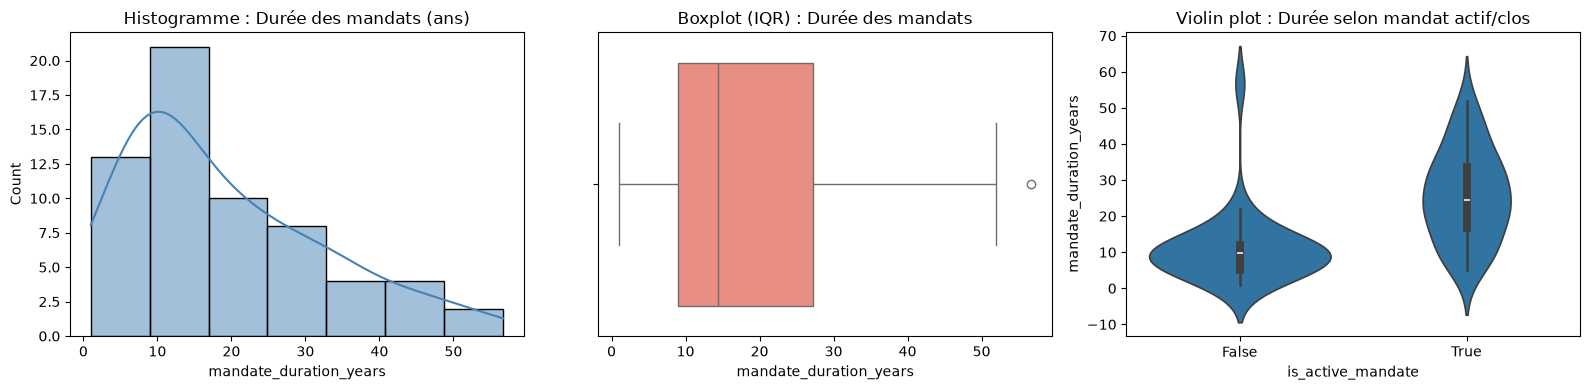

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Date de référence (pour calculer la durée des mandats encore actifs)
ref_date = pd.Timestamp("2026-01-01")
pa["effective_end"] = pa["appointment_end"].fillna(ref_date)
pa["mandate_duration_years"] = (pa["effective_end"] - pa["appointment_start"]).dt.days / 365.25
pa["age_at_end_or_2026"] = pa["effective_end"].dt.year - pa["recorded_birth_year"]

# résumé statistique 
def stats_and_outliers(df, col):
    s = df[col].dropna().astype(float)
    mean, std = s.mean(), s.std()
    med, q1, q3 = s.median(), s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    eam = np.mean(np.abs(s - med)) # écart abs médian 
    
    print(f"=== {col} (n={len(s)}) ===")
    print(f"  Moyenne : {mean:.2f} | Écart-type : {std:.2f}")
    print(f"  Médiane : {med:.2f} | Min : {s.min():.2f} | Max : {s.max():.2f} | Q1 : {q1:.2f} | Q3 : {q3:.2f} | IQR : {iqr:.2f}")
    
    # Détection d'outliers par IQR, Z-score (>3) et Z-score modifié (>3.5)
    iqr_mask = (df[col] < (q1 - 1.5 * iqr)) | (df[col] > (q3 + 1.5 * iqr))
    z_score = (df[col] - mean) / std
    mod_z_score = (df[col] - med) / eam
    
    outliers = df[iqr_mask | (z_score.abs() > 2.5)].copy()
    outliers["z_score"] = z_score
    outliers["mod_z_score"] = mod_z_score
    return outliers[["office_holder_name", "office_title", "institution_name", col, "is_active_mandate", "z_score", "mod_z_score"]]

print(stats_and_outliers(pa, "age_at_appointment"))
print("\n", stats_and_outliers(pa, "mandate_duration_years"))

# Affichage des mandats actifs anormalement longs (> 35 ans de pouvoir continu)
print("\nMandats toujours actifs en 2026 de plus de 35 ans")
print(pa[pa["is_active_mandate"] & (pa["mandate_duration_years"] > 35)][
    ["office_holder_name", "recorded_birth_year", "age_at_end_or_2026", "office_title", "institution_name", "appointment_start", "mandate_duration_years"]
].sort_values("mandate_duration_years", ascending=False))

# Visualisation (histo + boxplot + violin plot)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(pa["mandate_duration_years"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Histogramme : Durée des mandats (ans)")
sns.boxplot(x=pa["mandate_duration_years"], ax=axes[1], color="salmon")
axes[1].set_title("Boxplot (IQR) : Durée des mandats")
sns.violinplot(x="is_active_mandate", y="mandate_duration_years", data=pa, ax=axes[2])
axes[2].set_title("Violin plot : Durée selon mandat actif/clos")
plt.tight_layout()
plt.show()

In [29]:
# (1 ligne = 1 demande d'accès = 1 transaction)
sace_cases = sace.groupby("access_case_number").agg(
    site_code=("site_code", "first"),
    org_name=("requesting_organization_name", "first"),
    auth_agency=("authorizing_agency", "first"),
    purpose=("access_purpose", "first"),
    equipment=("equipment_category", "first"),
    conf_class=("confidentiality_class", "first"),
    start_time=("event_time", "min"),
    end_time=("event_time", "max"),
    n_events=("access_event_id", "count"),
    final_status=("new_status", "last")
).reset_index()

# vérif de la loi de puissance sur le nombre de demandes par organisation 
org_counts = sace_cases["org_name"].value_counts()
print("Top 5 des organisations demanderesses (sur 60 dossiers)")
print(org_counts.head(5))

# Matrice de co-occurrences en pourcentage par colonne
cooc_eq_conf = pd.crosstab(sace_cases["equipment"], sace_cases["conf_class"], normalize="index") * 100
print("\nCo-occurrence Équipement vs Confidentialité (% par ligne)")
print(cooc_eq_conf.round(1))

#  règle d'association 
# Règle X -> Y : {equipment == 'portable monitoring and cold-storage equipment'} -> {org_name == 'Horizon Field Research Cooperative'}
N = len(sace_cases)
X = sace_cases["equipment"] == "portable monitoring and cold-storage equipment"
Y = sace_cases["org_name"] == "Horizon Field Research Cooperative"

supp_X = X.sum() / N
supp_Y = Y.sum() / N
supp_XY = (X & Y).sum() / N
conf_XY = supp_XY / supp_X
lift_XY = conf_XY / supp_Y
leverage_XY = supp_XY - (supp_X * supp_Y)

print("\n=== Règle d'association : {Cold-Storage Equipment} -> {Horizon Field Research Cooperative} ===")
print(f"  Support absolu : {(X & Y).sum()} dossiers sur {N}")
print(f"  Support relatif: {supp_XY:.3f} ({supp_XY*100:.1f}%)")
print(f"  Confidence     : {conf_XY:.3f} ({conf_XY*100:.1f}%) -> 100% des unités réfrigérées sont demandées par Horizon !")
print(f"  Lift           : {lift_XY:.2f} (forte corrélation positive > 1)")
print(f"  Leverage       : {leverage_XY:.4f}")

Top 5 des organisations demanderesses (sur 60 dossiers)
org_name
Horizon Field Research Cooperative       18
Nordhaven Maritime Safety Agency          2
Valenne Laboratory Materials              2
Interregional Procurement Cooperative     2
Nordhaven Refrigeration Works             2
Name: count, dtype: int64

Co-occurrence Équipement vs Confidentialité (% par ligne)
conf_class                                      confidential  restricted  standard
equipment                                                                         
acoustic and camera equipment                           50.0        16.7      33.3
acoustic monitoring equipment                            8.3         8.3      83.3
camera equipment                                        25.0         0.0      75.0
maintenance tools                                       25.0         8.3      66.7
portable monitoring and cold-storage equipment          42.9        42.9      14.3
protective field equipment                       

In [30]:
# Anomalie  sur l'heure de passage dans les grottes 
sace["hour"] = sace["event_time"].dt.hour
print("Heure des événements selon l'activité (Toutes organisations vs Horizon)")
print(pd.crosstab([sace["requesting_organization_name"] == "Horizon Field Research Cooperative", sace["activity"]], sace["hour"]))

# individus agissant APRÈS leur décès????
deceased_info = pa[pa["departure_reason"] == "deceased"][["office_holder_name", "appointment_end"]].drop_duplicates()
sace_with_death = sace.merge(deceased_info, left_on="authorized_person_name", right_on="office_holder_name")
post_mortem_events = sace_with_death[sace_with_death["event_time"] > sace_with_death["appointment_end"]]

print("\nÉvénements signés par Elira Vaun APRÈS sa date de décès (2021-09-18) ??")
print(post_mortem_events[["access_event_id", "access_case_number", "site_code", "event_time", "activity", "requesting_organization_name", "appointment_end"]])

# Individus historiques du XIXe/XXe siècle toujours actifs sur le terrain en 2015-2025
historical_figures = ["J. Varlan", "Jonah Bell", "Julien Marot"]
print("\nFondateurs historiques (1883, 1923, 1969) actifs dans site_access (2015-2025)")
print(sace[sace["authorized_person_name"].isin(historical_figures)].groupby("authorized_person_name").agg(
    nb_events=("access_event_id", "count"),
    first_seen=("event_time", "min"),
    last_seen=("event_time", "max"),
    orgs=("requesting_organization_name", lambda s: list(s.unique()))
))

# Chronologie des entités dissoutes dans registered_entities 
re["founded_year"] = re["registration_date"].dt.year
re["dissolved_or_filing_year"] = re["last_filing_date"].dt.year
print("\nChaînes de succession d'entreprises (1838 a 2025)")
print(re.sort_values("founded_year")[
    ["registration_number", "legal_name", "registered_entity_type", "founded_year", "dissolved_or_filing_year", "current_status", "jurisdiction"]
].head(10))

Heure des événements selon l'activité (Toutes organisations vs Horizon)
hour                                                3   9   11  17  18
requesting_organization_name activity                                 
False                        access_completed        0   0  36   0   0
                             access_started          0   0   0  36   0
                             authorization_denied    0   6   0   0   0
                             authorization_granted   0  36   0   0   0
                             closure_recorded        0  42   0   0   0
                             request_submitted       0  42   0   0   0
                             technical_review        0  42   0   0   0
                             wildlife_review         0  28   0   0   0
True                         access_completed       18   0   0   0   0
                             access_started          0   0   0   0  18
                             authorization_denied    0   3   0   0   0
     

In [31]:
# 8 sites exclusifs de Horizon vs les plaintes citoyennes
horizon_sites = set(sace_cases[sace_cases["org_name"] == "Horizon Field Research Cooperative"]["site_code"])
other_sites = set(sace_cases[sace_cases["org_name"] != "Horizon Field Research Cooperative"]["site_code"])
print(f"Sites visités par Horizon ({len(horizon_sites)}) : {sorted(list(horizon_sites))}")
print(f"Intersection avec les 30 autres organisations : {len(horizon_sites & other_sites)} (Ségrégation spatiale totale !)")

#  traces de processus dans regulatory_cases
rce_traces = rce.groupby("case_number").agg(
    source=("initiating_source", "first"),
    unit=("assigned_unit", "first"),
    subject=("subject_name", "first"),
    site_code=("related_site_code", "first"),
    shipment=("related_shipment_number", "first"),
    trace=("activity", lambda s: " -> ".join(s)),
    final_outcome=("outcome", "last")
).reset_index()

print("\nTraces de processus pour les 10 plaintes de la société civile (civil society referral)")
csr_traces = rce_traces[rce_traces["source"] == "civil society referral"]
print(csr_traces[["case_number", "subject", "site_code", "shipment", "trace", "final_outcome"]].to_string(index=False))

# Calcul de la matrice de transition / dépendance
rce["next_activity"] = rce.groupby("case_number")["activity"].shift(-1)
transitions = pd.crosstab(rce["activity"], rce["next_activity"].fillna("END"))
print("\n--- Matrice de transition des activités réglementaires ---")
print(transitions)

Sites visités par Horizon (8) : ['AVL-MAR', 'AVL-ORR', 'AVL-VEL', 'KNT-KES', 'KNT-LUM', 'KNT-SEN', 'TMB-NAC', 'TMB-PEL']
Intersection avec les 30 autres organisations : 0 (Ségrégation spatiale totale !)

Traces de processus pour les 10 plaintes de la société civile (civil society referral)
  case_number                                subject site_code       shipment                                                                                                                                 trace            final_outcome
REG-2018-0001 Avelora Agricultural Resilience Agency   AVL-MAR SHP-2018-00032                                case_opened -> evidence_received -> triage_review -> technical_review -> finding_issued -> case_closed              case closed
REG-2019-0002  Kintara Cave and Pollinator Authority   KNT-KES SHP-2018-00007                                case_opened -> evidence_received -> triage_review -> technical_review -> finding_issued -> case_closed              case close

In [32]:
import networkx as nx
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

# graphe  Acteurs <-> Organisations dans site_access
G = nx.Graph()
for _, row in sace.dropna(subset=["authorized_person_name", "requesting_organization_name"]).iterrows():
    person = row["authorized_person_name"]
    org = row["requesting_organization_name"]
    G.add_node(person, bipartite="person")
    G.add_node(org, bipartite="org")
    if G.has_edge(person, org):
        G[person][org]["weight"] += 1
    else:
        G.add_edge(person, org, weight=1)

# Degree, Closeness, Betweenness
deg_cent = nx.degree_centrality(G)
bet_cent = nx.betweenness_centrality(G, weight="weight")
clos_cent = nx.closeness_centrality(G)

centrality_df = pd.DataFrame({
    "node": list(G.nodes()),
    "type": [G.nodes[n]["bipartite"] for n in G.nodes()],
    "degree": [G.degree(n) for n in G.nodes()],
    "betweenness": [bet_cent[n] for n in G.nodes()],
    "closeness": [clos_cent[n] for n in G.nodes()]
}).sort_values("betweenness", ascending=False)

print("Top 10 des noeuds les plus centraux (ponts/betweenness)")
print(centrality_df.head(10).to_string(index=False))

# Textmining, TF-IDF (N-grams 1 à 2) et Topic Modeling LSA (SVD) sur investigative_docs 
vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), max_features=500)
tfidf_matrix = vectorizer.fit_transform(paid["text"])
feature_names = vectorizer.get_feature_names_out()

lsa = TruncatedSVD(n_components=3, random_state=42)
lsa_topic_matrix = lsa.fit_transform(tfidf_matrix)

print("\nTop 10 des termes/bigrams par topic (LSA/SVD)")
for topic_idx, comp in enumerate(lsa.components_):
    top_terms = [feature_names[i] for i in comp.argsort()[:-11:-1]]
    print(f"Topic {topic_idx + 1} : {', '.join(top_terms)}")

# Termes TF-IDF les plus discriminants des documents restreints vs publics
restricted_mask = (paid["public_or_restricted"] == "restricted").to_numpy()
restricted_mean_tfidf = np.asarray(tfidf_matrix[restricted_mask].mean(axis=0)).ravel()
top_restricted_words = [feature_names[i] for i in restricted_mean_tfidf.argsort()[:-16:-1]]

print("\nMots-clés TF-IDF caractérisant les documents 'restricted' :", top_restricted_words)

Top 10 des noeuds les plus centraux (ponts/betweenness)
                                 node   type  degree  betweenness  closeness
      Civic Health Purchasing Network    org      14     0.108870   0.425414
                         Farah Ferran person      12     0.070125   0.478261
         Valenne Laboratory Materials    org      11     0.055920   0.411765
  Kintara Field Equipment Cooperative    org      11     0.055361   0.420765
               Auric Medical Supplies    org      11     0.055306   0.407407
Interregional Procurement Cooperative    org      10     0.053170   0.403141
 Valenne Public Procurement Authority    org      12     0.052144   0.430168
     Nordhaven Maritime Safety Agency    org      12     0.050938   0.398964
   Horizon Field Research Cooperative    org      46     0.048620   0.706422
                            Mara Venn person       8     0.040477   0.455621

Top 10 des termes/bigrams par topic (LSA/SVD)
Topic 1 : records, document, justice, accountabili

In [ ]:
#PUB-510045
doc_pub45 = paid[paid["document_id"] == "PUB-510045"].iloc[0]

print(f"=== {doc_pub45['document_id']} : {doc_pub45['title']} ===")
print(f"Auteur        : {doc_pub45['author_name']}")
print(f"Organisme     : {doc_pub45['author_organization']}")
print(f"Date          : {doc_pub45['document_date']}")
print(f"Confidentialité : {doc_pub45['public_or_restricted']}")
print("\n" + "="*50 + " TEXTE DU DOCUMENT " + "="*50 + "\n")
print(doc_pub45["text"])

=== PUB-510045 : Restricted Review of Recurrent Executive Health Interventions ===
Auteur        : Dr. Lysa Quen
Organisme     : Orison Medical Audit Board
Date          : 2022-07-08 00:00:00
Confidentialité : restricted

================================================== TEXTE DU DOCUMENT ==================================================

PURPOSE
This restricted briefing summarizes a small set of senior office-holders and corporate leaders who have received recurrent confidential health interventions through overlapping providers.

EVIDENCE REVIEWED
Appointment archives, professional licences, facility records, encounter dates, and restricted procedure summaries were compared. Eight individuals show repeated specialist attendance over several years. Their public roles differ, and no common diagnosis is recorded in the accessible files. The same limited group of clinicians and facilities appears more often than expected from the individuals' home regions and ordinary referral pathways